# Expérience 1 — XGBoost, jour de l’année et saison

Le calendrier aide-t-il XGBoost à prévoir la température maximale du lendemain ?


On prédit **Tmax de demain** à partir de la météo d'aujourd'hui.
On suppose donc être en fin de journée, une fois toutes les observations du jour connues.
Les journées sont définies en UTC. Les données ERA5 sont rétrospectives : ce n'est pas
encore une simulation de prévision météo en temps réel.

Tout le code de l'expérience est dans ce notebook. Si le CSV manque, lancer depuis
la racine du projet : `nix develop --command python scripts/download_four_neighbors.py`.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error
from IPython.display import display


/nix/store/nigd81xp2fkmdlyh0a45lk1k21q2h1mk-python3-3.10.6-env/lib/python3.10/site-packages/xgboost/compat.py:36: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import MultiIndex, Int64Index


## 1. Charger les données

Le CSV contient Nantes et quatre voisins. On commence avec Nantes seulement.


In [2]:
DATA_PATH = Path("../data/weather_five_points_daily.csv")
toutes_les_donnees = pd.read_csv(DATA_PATH, parse_dates=["date"])

display(toutes_les_donnees[["point", "lat", "lon"]].drop_duplicates())

nantes = toutes_les_donnees[toutes_les_donnees["point"] == "nantes"].copy()
nantes = nantes.sort_values("date").reset_index(drop=True)

assert not toutes_les_donnees.duplicated(["point", "date"]).any()
assert not toutes_les_donnees.isna().any().any()

print(f"{len(nantes)} journées, du {nantes['date'].min().date()} au {nantes['date'].max().date()}")
display(nantes.head())


,point,lat,lon
0,nantes,47.25,-1.5
997,nord,48.00,-1.5
1994,sud,46.50,-1.5
2991,est,47.25,-0.5
3988,ouest,47.25,-2.5


997 journées, du 2024-01-01 au 2026-09-23


,date,temperature_max,temperature_min,temperature_mean,relative_humidity_mean,dew_point_mean,pressure_msl_mean,cloud_cover_mean,wind_speed_mean,wind_speed_max,precipitation_sum,soil_moisture_mean,u_mean,v_mean,shortwave_radiation_sum_MJ_m2,point,lat,lon
0,2024-01-01,12.2,7.4,9.795833,89.500000,8.150000,1010.704167,95.125000,5.681667,9.92,11.9,0.404625,3.859417,4.020167,3.5712,nantes,47.25,-1.5
1,2024-01-02,13.6,11.8,12.566667,91.000000,11.104167,1002.066667,78.666667,9.690833,12.38,24.1,0.431042,7.241177,6.202577,0.5112,nantes,47.25,-1.5
2,2024-01-03,12.7,10.4,11.729167,83.833333,9.087500,1005.200000,50.041667,8.166250,10.02,5.2,0.416833,7.547495,2.867414,3.4452,nantes,47.25,-1.5
3,2024-01-04,13.2,7.8,10.291667,89.125000,8.570833,1006.791667,77.375000,5.616667,9.67,5.4,0.414792,3.366567,4.028317,2.5416,nantes,47.25,-1.5
4,2024-01-05,10.8,4.5,6.633333,90.666667,5.133333,1006.904167,54.041667,2.215417,3.30,0.0,0.403125,1.907217,-0.784464,5.4072,nantes,47.25,-1.5


## 2. Construire la cible : la Tmax du lendemain

Pour chaque date J, on cherche la température à la date **J + 1 jour**.
Cette correspondance sur la date évite de confondre « ligne suivante » et « lendemain »
si un jour manque. La dernière journée est retirée car son lendemain n'est pas connu.


In [3]:
temperature_par_date = nantes.set_index("date")["temperature_max"]

nantes["date_cible"] = nantes["date"] + pd.Timedelta(days=1)
nantes["tmax_demain"] = nantes["date_cible"].map(temperature_par_date)
nantes = nantes.dropna(subset=["tmax_demain"]).copy()

display(nantes[["date", "temperature_max", "date_cible", "tmax_demain"]].head())


,date,temperature_max,date_cible,tmax_demain
0,2024-01-01,12.2,2024-01-02,13.6
1,2024-01-02,13.6,2024-01-03,12.7
2,2024-01-03,12.7,2024-01-04,13.2
3,2024-01-04,13.2,2024-01-05,10.8
4,2024-01-05,10.8,2024-01-06,9.3


## 3. Ajouter le jour de l'année et la saison

On utilise le calendrier de **demain**, dont on connaît déjà la date.
Le jour de l'année est représenté par un sinus et un cosinus : fin décembre reste
proche de début janvier. Le calcul tient compte des années à 365 ou 366 jours.

La saison est représentée par quatre colonnes 0/1. On n'ajoute ni mois ni année
comme variables supplémentaires.


In [4]:
dates = nantes["date_cible"]
nantes["jour_annee"] = dates.dt.dayofyear

jours_dans_annee = np.where(dates.dt.is_leap_year, 366, 365)
angle = 2 * np.pi * (nantes["jour_annee"] - 1) / jours_dans_annee
nantes["jour_sin"] = np.sin(angle)
nantes["jour_cos"] = np.cos(angle)

saisons_par_mois = {
    12: "hiver", 1: "hiver", 2: "hiver",
    3: "printemps", 4: "printemps", 5: "printemps",
    6: "ete", 7: "ete", 8: "ete",
    9: "automne", 10: "automne", 11: "automne",
}
nantes["saison"] = dates.dt.month.map(saisons_par_mois)
saisons = pd.get_dummies(nantes["saison"], prefix="saison")
nantes = pd.concat([nantes, saisons], axis=1)

display(nantes[["date_cible", "jour_annee", "jour_sin", "jour_cos", "saison"]].head())


,date_cible,jour_annee,jour_sin,jour_cos,saison
0,2024-01-02,2,0.017166,0.999853,hiver
1,2024-01-03,3,0.034328,0.999411,hiver
2,2024-01-04,4,0.051479,0.998674,hiver
3,2024-01-05,5,0.068615,0.997643,hiver
4,2024-01-06,6,0.085731,0.996318,hiver


## 4. Choisir les variables

On compare la météo seule à la même météo enrichie du calendrier. XGBoost utilise des arbres : on ne standardise pas les données ici.


In [5]:
colonnes_meteo = [
    "temperature_max", "temperature_min", "temperature_mean",
    "relative_humidity_mean", "dew_point_mean", "pressure_msl_mean",
    "cloud_cover_mean", "wind_speed_mean", "wind_speed_max",
    "precipitation_sum", "soil_moisture_mean", "shortwave_radiation_sum_MJ_m2",
]
colonnes_temps = ["jour_sin", "jour_cos"] + list(saisons.columns)
colonnes_temporelles = colonnes_meteo + colonnes_temps


## 5. Séparer le passé et le futur

Pas de mélange aléatoire des journées. Au début du test, les températures des jours
d'entraînement sont déjà connues. La température de chaque jour cible du test reste cachée au modèle.


In [6]:
# Les 80 % premières dates pour apprendre, les 20 % dernières pour évaluer.
position_coupure = int(len(nantes) * 0.8)
date_test = nantes.iloc[position_coupure]["date_cible"]

train = nantes[nantes["date_cible"] < date_test].copy()
test = nantes[nantes["date_cible"] >= date_test].copy()

y_train = train["tmax_demain"]
y_test = test["tmax_demain"]
persistance = test["temperature_max"]

print(f"Entraînement : {len(train)} jours, jusqu'au {train['date_cible'].max().date()}")
print(f"Test : {len(test)} jours, à partir du {test['date_cible'].min().date()}")


Entraînement : 796 jours, jusqu'au 2026-03-07
Test : 200 jours, à partir du 2026-03-08


## 6. Entraîner les deux XGBoost

Même configuration, mêmes journées ; seules les colonnes changent.


In [7]:
modele_meteo = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=2,
)
modele_meteo.fit(train[colonnes_meteo], y_train)
prediction_meteo = modele_meteo.predict(test[colonnes_meteo])


/nix/store/nigd81xp2fkmdlyh0a45lk1k21q2h1mk-python3-3.10.6-env/lib/python3.10/site-packages/xgboost/data.py:262: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  elif isinstance(data.columns, (pd.Int64Index, pd.RangeIndex)):
/nix/store/nigd81xp2fkmdlyh0a45lk1k21q2h1mk-python3-3.10.6-env/lib/python3.10/site-packages/xgboost/data.py:262: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  elif isinstance(data.columns, (pd.Int64Index, pd.RangeIndex)):


In [8]:
modele_temporel = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=2,
)
modele_temporel.fit(train[colonnes_temporelles], y_train)
prediction_temporelle = modele_temporel.predict(test[colonnes_temporelles])


/nix/store/nigd81xp2fkmdlyh0a45lk1k21q2h1mk-python3-3.10.6-env/lib/python3.10/site-packages/xgboost/data.py:262: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  elif isinstance(data.columns, (pd.Int64Index, pd.RangeIndex)):
/nix/store/nigd81xp2fkmdlyh0a45lk1k21q2h1mk-python3-3.10.6-env/lib/python3.10/site-packages/xgboost/data.py:262: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  elif isinstance(data.columns, (pd.Int64Index, pd.RangeIndex)):


## 7. Comparer les erreurs

La MAE est l’erreur absolue moyenne en degrés Celsius.


In [9]:
scores = pd.DataFrame({
    "modele": ["Persistance", "XGBoost météo", "XGBoost + jour et saison"],
    "MAE_C": [
        mean_absolute_error(y_test, persistance),
        mean_absolute_error(y_test, prediction_meteo),
        mean_absolute_error(y_test, prediction_temporelle),
    ],
})
display(scores.round(3))


,modele,MAE_C
0,Persistance,2.182
1,XGBoost météo,2.550
2,XGBoost + jour et saison,2.542


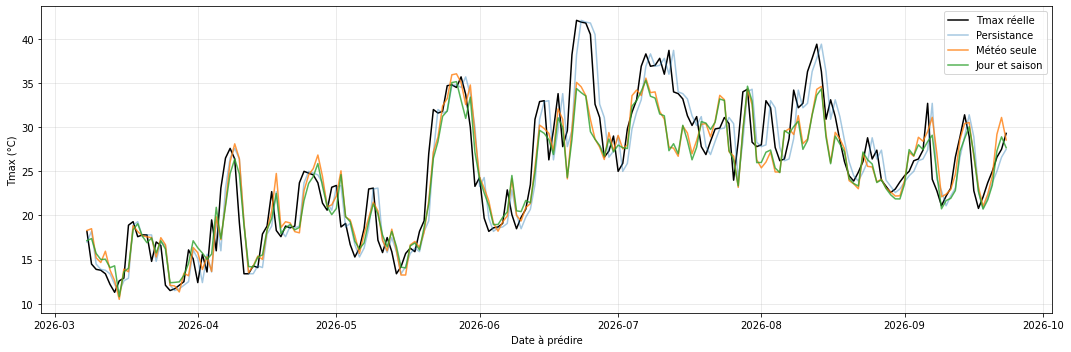

In [10]:
plt.figure(figsize=(15, 5))
plt.plot(test["date_cible"], y_test, label="Tmax réelle", color="black")
plt.plot(test["date_cible"], persistance, label="Persistance", alpha=0.4)
plt.plot(test["date_cible"], prediction_meteo, label="Météo seule", alpha=0.8)
plt.plot(test["date_cible"], prediction_temporelle, label="Jour et saison", alpha=0.8)
plt.xlabel("Date à prédire")
plt.ylabel("Tmax (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()


## À retenir

Une MAE plus basse signifie une meilleure prévision moyenne. Les modèles utilisent
les mêmes dates de test et les mêmes paramètres : on change seulement les variables d'entrée.
La persistance signifie « demain aura la même Tmax qu'aujourd'hui ».

On garde ces paramètres fixés, sans les modifier à partir des résultats du test.
Ces dates ayant déjà été regardées lors d'essais précédents, les résultats restent exploratoires.
